<a href="https://colab.research.google.com/github/madsondeluna/aula_dinamica_molecular/blob/main/legado/MD_GMX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tutoriais Introdutórios de Dinâmica Molecular com GROMACS


## Antes de começar: mantenha a sessão viva e salve no Drive

Execute as duas células abaixo **antes de qualquer outra coisa**.

**Por quê?**
- O Colab desconecta sessões inativas após ~90 min. O keep-alive evita isso.
- Os arquivos em `/content` somem quando a sessão encerra. Salvando no Drive eles persistem.


In [ ]:
# Mantem a sessao ativa clicando automaticamente no botao de conexao
# Execute esta celula logo apos abrir o notebook
from IPython.display import Javascript, display
display(Javascript("""
function keepAlive() {
    const btn = document.querySelector('colab-toolbar-button#connect');
    if (btn) { btn.click(); console.log('Colab keep-alive ping'); }
}
setInterval(keepAlive, 60000);  // a cada 60 segundos
console.log('Keep-alive iniciado.');
"""))


<IPython.core.display.Javascript object>

In [ ]:
# Monta o Google Drive (opcional) e define o diretorio de trabalho
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/aula_dinamica_molecular'
    os.makedirs(WORK_DIR, exist_ok=True)
    os.chdir(WORK_DIR)
    print('Trabalhando no Google Drive:', os.getcwd())
except Exception:
    os.chdir('/content')
    print('Drive nao montado — trabalhando em /content (arquivos nao persistem apos a sessao)')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Trabalhando no Google Drive: /content/drive/MyDrive/aula_dinamica_molecular


# Instalação e Configuração do Ambiente

Todos os exercícios utilizam o **campo de força CHARMM36m** (julho 2022), que **não está incluído**
na instalação padrão do GROMACS e deve ser baixado separadamente.

> **Ambiente:** Todas as simulações rodam na CPU via GROMACS instalado pelo apt-get.
> O Colab gratuito é suficiente para este tutorial.


In [ ]:
import os, sys, subprocess

def cached(files, label):
    """Retorna True se todos os arquivos existirem — etapa ja concluida."""
    missing = [f for f in files if not os.path.exists(f)]
    if not missing:
        print(f"  ja pronto: {label}")
        return True
    return False

# GROMACS (instalacao de sistema — sempre necessaria na sessao)
if not os.path.exists('/usr/bin/gmx'):
    os.system('apt-get update -q && apt-get install -y -q gromacs')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'py3Dmol'], capture_output=True)
os.system("gmx --version 2>&1 | grep 'GROMACS version'")
print('Ambiente pronto.')

# ── Helpers de visualizacao (disponíveis em todas as celulas seguintes) ──────
import py3Dmol, numpy as np

SS_CS = {'prop': 'ss', 'map': {'h': '#FF4757', 's': '#2979FF', 'l': '#B0BEC5', 'c': '#B0BEC5', '': '#B0BEC5'}}  # helix=vermelho, sheet=azul, loop=cinza

def draw_box(view, gro_content, color='#1a3a6b', lw=2):
    lines = [l for l in gro_content.strip().split('\n') if l.strip()]
    if not lines:
        return
    try:
        vals = [float(x) for x in lines[-1].split()]
    except ValueError:
        return
    if len(vals) == 3:
        a, b, c = vals
        V = np.array([[a,0,0],[0,b,0],[0,0,c]]) * 10
    elif len(vals) == 9:
        v1x,v2y,v3z,v1y,v1z,v2x,v2z,v3x,v3y = vals
        V = np.array([[v1x,v1y,v1z],[v2x,v2y,v2z],[v3x,v3y,v3z]]) * 10
    else:
        return
    O = np.zeros(3)
    corners = [O, V[0], V[1], V[2],
               V[0]+V[1], V[0]+V[2], V[1]+V[2], V[0]+V[1]+V[2]]
    edges = [(0,1),(0,2),(0,3),(1,4),(1,5),(2,4),(2,6),(3,5),(3,6),(4,7),(5,7),(6,7)]
    for i,j in edges:
        a_,b_ = corners[i], corners[j]
        view.addLine({'start':{'x':float(a_[0]),'y':float(a_[1]),'z':float(a_[2])},
                       'end':  {'x':float(b_[0]),'y':float(b_[1]),'z':float(b_[2])},
                       'color':color,'linewidth':lw})

def viz_gro(gro_content, title='', width=700, height=450):
    """Sistema completo: proteina (SS distintas + cadeias laterais), agua translucida, ions, caixa."""
    view = py3Dmol.view(width=width, height=height)
    view.addModel(gro_content, 'gro')
    prot = {'not': {'resn': ['SOL','NA','CL']}}
    view.setStyle(prot, {'cartoon': {'colorscheme': SS_CS},
                          'stick':   {'colorscheme': SS_CS, 'radius': 0.12}})
    view.setStyle({'resn': 'SOL'},
                  {'stick': {'color': '#99ccff', 'radius': 0.12, 'opacity': 0.18}})
    view.addStyle({'resn': 'NA'}, {'sphere': {'color': '#3355ff', 'radius': 0.45}})
    view.addStyle({'resn': 'CL'}, {'sphere': {'color': '#22bb44', 'radius': 0.50}})
    draw_box(view, gro_content)
    view.setBackgroundColor('#f0f4f8')
    view.zoomTo()
    if title: print(title)
    view.show()

def viz_pdb(pdb_content, title='', width=700, height=420):
    """Proteina a partir de PDB: cartoon com SS distintas + cadeias laterais."""
    view = py3Dmol.view(width=width, height=height)
    view.addModel(pdb_content, 'pdb')
    view.setStyle({}, {'cartoon': {'colorscheme': SS_CS},
                          'stick':   {'colorscheme': SS_CS, 'radius': 0.10}})
    view.setBackgroundColor('#f0f4f8')
    view.zoomTo()
    if title: print(title)
    view.show()


Ambiente pronto.


In [ ]:
import os
mdp_files = ['ions.mdp', 'minim.mdp', 'nvt.mdp', 'npt.mdp', 'md.mdp']
if not cached(mdp_files, 'arquivos .mdp'):
    BASE = 'https://raw.githubusercontent.com/madsondeluna/aula_dinamica_molecular/main/legado/mdp'
    for f in mdp_files:
        os.system(f'wget -q {BASE}/{f} -O {f}')
    print('Arquivos .mdp baixados.')


  ja pronto: arquivos .mdp


In [ ]:
import os
if not cached(['charmm36-jul2022.ff/forcefield.itp'], 'CHARMM36m'):
    os.system('wget -q "https://mackerell.umaryland.edu/download.php?filename=CHARMM_ff_params_files/charmm36-jul2022.ff.tgz" -O charmm36-jul2022.ff.tgz')
    os.system('tar xzf charmm36-jul2022.ff.tgz')
    print('CHARMM36m baixado e descompactado.')


  ja pronto: CHARMM36m


In [ ]:
# Corrigir bug no charmm36-jul2022.ff: bloco [ MET1 ] em ethers.n.tdb
# O nome 'MET1' no arquivo de eteres (para grupo metila terminal) conflita com
# o bloco N-terminal do amino acido MET (metionina).
# Solucao: renomear [ MET1 ] para [ EMETH1 ] no arquivo de eteres.
# Isso nao afeta simulacoes de amino acidos (ethers.n.tdb nao e usado para proteinas).

import re

filepath = 'charmm36-jul2022.ff/ethers.n.tdb'
with open(filepath, 'r') as f:
    content = f.read()

if '[ MET1 ]' in content:
    content = content.replace('[ MET1 ]', '[ EMETH1 ]')
    with open(filepath, 'w') as f:
        f.write(content)
    print('Patch aplicado: [ MET1 ] renomeado para [ EMETH1 ] em ethers.n.tdb')
    print('Causa raiz: conflito de nome entre terminus de eter e N-terminal de Met')
else:
    print('Nenhum patch necessario (bloco MET1 nao encontrado)')

Nenhum patch necessario (bloco MET1 nao encontrado)


## Configurações Obrigatórias do CHARMM36m

As seguintes configurações devem ser usadas em **todas as etapas** da simulação. Elas já estão definidas nos arquivos `.mdp` deste repositório:

```
vdw-modifier  = force-switch   # chaveamento suave das forcas de vdW
rvdw-switch   = 1.0            # inicio do chaveamento (nm)
rvdw          = 1.2            # cutoff van der Waals (nm)
rcoulomb      = 1.2            # cutoff eletrostatico (nm)
rlist         = 1.4            # cutoff da lista de vizinhos (nm)
dispcorr      = no             # sem correcao de dispersao de longo alcance
constraints   = h-bonds        # apenas ligacoes com H sao restritas
ref_t         = 298            # temperatura de referencia (K)
```


# Exercício 1 — Ubiquitina em Água (1UBQ)

A ubiquitina é uma proteína globular de 76 resíduos com carga líquida nula, bem caracterizada experimentalmente — sistema modelo ideal para o primeiro protocolo.

**Fluxo de trabalho:**
```
1UBQ.pdb
  └─ pdb2gmx (CHARMM36m + TIP3P)        → ubiquitin.gro + topol.top + posre.itp
  └─ editconf (caixa cubica, d=1.2 nm)    → ubiquitin_box.gro
  └─ solvate                            → ubiquitin_solv.gro
  └─ genion (0.1 M NaCl)               → ubiquitin_solv_ions.gro
  └─ mdrun minimizacao (emtol=500)      → em.gro
  └─ mdrun NVT 20 ps (298 K)           → nvt.gro
  └─ mdrun NPT 50 ps (1 bar)           → npt.gro
  └─ mdrun MD 100 ps                     → md_0_100.xtc
  └─ analise (RMSD, RMSF, Hbond, DSSP)
```


In [ ]:
import os
if not cached(['1UBQ.pdb'], '1UBQ.pdb'):
    os.system('wget -q https://files.rcsb.org/download/1UBQ.pdb')
print(f"Linhas ATOM:   {sum(1 for l in open('1UBQ.pdb') if l.startswith('ATOM'))}")
print(f"Linhas HETATM: {sum(1 for l in open('1UBQ.pdb') if l.startswith('HETATM'))}")


  ja pronto: 1UBQ.pdb
Linhas ATOM:   602
Linhas HETATM: 58


In [ ]:
# Visualizacao: 1UBQ.pdb original — proteina + aguas cristalograficas
with open('1UBQ.pdb') as f:
    pdb_raw = f.read()

view = py3Dmol.view(width=700, height=420)
view.addModel(pdb_raw, 'pdb')
view.setStyle({'chain': 'A', 'hetflag': False},
              {'cartoon': {'colorscheme': SS_CS}, 'stick': {'colorscheme': SS_CS, 'radius': 0.10}})
view.addStyle({'resn': 'HOH'}, {'sphere': {'color': 'cyan', 'radius': 0.40, 'opacity': 0.85}})
view.addStyle({'resi': '1'},   {'stick': {'color': '#FF4757', 'radius': 0.25}})
view.setBackgroundColor('#f0f4f8')
view.zoomTo()
view.show()
print("CYAN: 58 aguas cristalograficas sem H | VERMELHO: MET1 (N-terminal)")
print()
print("Por que remover as aguas?")
print("  RX nao detecta H bem — pdb2gmx nao consegue reconstruir as aguas parciais")
print("  Vamos adicionar solvente completo na etapa de solvatacao")


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

CYAN: 58 aguas cristalograficas sem H | VERMELHO: MET1 (N-terminal)

Por que remover as aguas?
  RX nao detecta H bem — pdb2gmx nao consegue reconstruir as aguas parciais
  Vamos adicionar solvente completo na etapa de solvatacao


In [ ]:
# Remover aguas cristalograficas (HETATM) — manter apenas atomos da proteina (ATOM)
with open('1UBQ.pdb') as f:
    lines = f.readlines()

protein_lines = [l for l in lines if l.startswith('ATOM')]
with open('1UBQ_protein.pdb', 'w') as f:
    f.writelines(protein_lines)
    f.write('END\n')

print(f"1UBQ_protein.pdb criado: {len(protein_lines)} atomos (proteina pura, sem aguas)")

1UBQ_protein.pdb criado: 602 atomos (proteina pura, sem aguas)


In [ ]:
# Visualizacao: 1UBQ_protein.pdb — aguas cristalograficas removidas
with open('1UBQ_protein.pdb') as f:
    pdb_clean = f.read()

view = py3Dmol.view(width=700, height=420)
view.addModel(pdb_clean, 'pdb')
view.setStyle({}, {'cartoon': {'colorscheme': SS_CS}, 'stick': {'colorscheme': SS_CS, 'radius': 0.10}})
view.addStyle({'resi': '1'},  {'stick': {'color': '#FF4757', 'radius': 0.25}})
view.addStyle({'resi': '76'}, {'stick': {'color': '#2979FF', 'radius': 0.25}})
view.setBackgroundColor('#f0f4f8')
view.zoomTo()
view.show()
n = sum(1 for l in pdb_clean.splitlines() if l.startswith('ATOM'))
print(f'{n} atomos | VERMELHO: MET1 (N-term) | AZUL: GLY76 (C-term) | Pronto para pdb2gmx')


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

602 atomos | VERMELHO: MET1 (N-term) | AZUL: GLY76 (C-term) | Pronto para pdb2gmx


## Passo 1 — Preparação da Topologia

`gmx pdb2gmx` define estados de protonação, constrói hidrogênios ausentes e gera a topologia no contexto do campo de força escolhido. O modelo de água é passado diretamente via `-water tip3p`, então a única seleção interativa é o campo de força:

- `1` → CHARMM36 (opção 1 quando `charmm36-jul2022.ff` está no diretório de trabalho)

Arquivos gerados: `ubiquitin.gro`, `topol.top`, `posre.itp`

In [ ]:
import os
# Filtrar apenas linhas ATOM (remove aguas cristalograficas sem H)
if not cached(['1UBQ_protein.pdb'], '1UBQ_protein.pdb'):
    with open('1UBQ.pdb') as f:
        lines = [l for l in f if l.startswith('ATOM')]
    with open('1UBQ_protein.pdb', 'w') as f:
        f.writelines(lines)
    print(f'1UBQ_protein.pdb criado: {len(lines)} linhas ATOM')

if not cached(['ubiquitin.gro', 'topol.top', 'posre.itp'], 'pdb2gmx'):
    os.system('echo "1" | gmx pdb2gmx -f 1UBQ_protein.pdb -o ubiquitin.gro -water tip3p 2>&1')


  ja pronto: 1UBQ_protein.pdb
  ja pronto: pdb2gmx


In [ ]:
# Visualizacao: ubiquitin.gro — H adicionados, terminais ionizados
with open('ubiquitin.gro') as f:
    gro_data = f.read()

view = py3Dmol.view(width=700, height=420)
view.addModel(gro_data, 'gro')
view.setStyle({}, {'cartoon': {'colorscheme': SS_CS}, 'stick': {'colorscheme': SS_CS, 'radius': 0.10}})
view.addStyle({'resi': '1'},  {'stick': {'color': '#FF4757', 'radius': 0.22}})
view.addStyle({'resi': '76'}, {'stick': {'color': '#2979FF', 'radius': 0.22}})
view.setBackgroundColor('#f0f4f8')
view.zoomTo()
view.show()
print("VERMELHO: N-terminal MET1 (NH3+) | AZUL: C-terminal GLY76 (COO-)")
print("Arquivos gerados: ubiquitin.gro, topol.top, posre.itp")


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

VERMELHO: N-terminal MET1 (NH3+) | AZUL: C-terminal GLY76 (COO-)
Arquivos gerados: ubiquitin.gro, topol.top, posre.itp


## Passo 2 — Definição da Caixa e Solvatação

Usamos uma **caixa cúbica** (`-bt cubic`): ocupa Distância proteína–borda: 1.2 nm.

> `spc216.gro` é uma caixa de água pré-equilibrada usada para qualquer modelo de três pontos (SPC, SPC/E, TIP3P). O sistema converge para as propriedades do TIP3P durante a equilibração.


In [ ]:
import os
if not cached(['ubiquitin_box.gro'], 'editconf'):
    os.system('gmx editconf -f ubiquitin.gro -o ubiquitin_box.gro -c -d 1.2 -bt cubic')


  ja pronto: editconf


In [ ]:
# Visualizacao: proteina centrada na caixa cubica (sem agua)
with open('ubiquitin_box.gro') as f:
    gro_box = f.read()

view = py3Dmol.view(width=700, height=450)
view.addModel(gro_box, 'gro')
view.setStyle({}, {'cartoon': {'colorscheme': SS_CS}, 'stick': {'colorscheme': SS_CS, 'radius': 0.10}})
draw_box(view, gro_box)
view.setBackgroundColor('#f0f4f8')
view.zoomTo()
view.show()
dims = [float(x)*10 for x in gro_box.strip().split('\n')[-1].split()[:3]]
print(f'Caixa cubica: {dims[0]:.1f} x {dims[1]:.1f} x {dims[2]:.1f} A')
print('Proteina centrada | margem >= 1.2 nm ate qualquer borda')


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Caixa cubica: 68.4 x 68.4 x 68.4 A
Proteina centrada | margem >= 1.2 nm ate qualquer borda


In [ ]:
import os
if not cached(['ubiquitin_solv.gro'], 'solvate'):
    # Remove entradas SOL/NA/CL acumuladas em topol.top (seguranca para re-execucao)
    with open('topol.top') as f:
        lines = f.readlines()
    clean = []
    for line in lines:
        parts = line.split()
        if len(parts) == 2 and parts[0] in ('SOL','NA','CL'):
            try: int(parts[1]); continue
            except ValueError: pass
        clean.append(line)
    with open('topol.top', 'w') as f:
        f.writelines(clean)
    os.system('gmx solvate -cp ubiquitin_box.gro -cs spc216.gro -o ubiquitin_solv.gro -p topol.top')


  ja pronto: solvate


In [ ]:
# Visualizacao: sistema solvatado — proteina + agua TIP3P
with open('ubiquitin_solv.gro') as f:
    gro_solv = f.read()

viz_gro(gro_solv, 'Apos solvate — proteina + agua TIP3P')
lines = gro_solv.strip().split('\n')
n_sol = sum(1 for l in lines if 'SOL' in l and 'OW' in l)
print(f'Moleculas de agua TIP3P: ~{n_sol}')


Apos solvate — proteina + agua TIP3P


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Moleculas de agua TIP3P: ~10089


## Passo 3 — Adição de Íons (0.1 M NaCl)

A ubiquitina tem carga líquida zero — não é necessário neutralizar. Adicionamos 0.1 M de NaCl para simular condições fisiológicas.

`grompp` monta o `.tpr` (binário com coordenadas + topologia + parâmetros). `genion` substitui moléculas de água aleatórias pelos íons Na⁺ e Cl⁻.


In [ ]:
import os
if not cached(['ubiquitin_solv_ions.gro'], 'genion'):
    os.system('gmx grompp -f ions.mdp -c ubiquitin_solv.gro -p topol.top -o ions.tpr')
    os.system('echo "SOL" | gmx genion -s ions.tpr -o ubiquitin_solv_ions.gro -p topol.top -pname NA -nname CL -conc 0.1')


  ja pronto: genion


In [ ]:
# Visualizacao: sistema com ions — 0.1 M NaCl
with open('ubiquitin_solv_ions.gro') as f:
    gro_ions = f.read()

viz_gro(gro_ions, 'Apos genion — proteina + agua + NaCl 0.1 M')
lines = gro_ions.strip().split('\n')
n_na = sum(1 for l in lines if ' NA ' in l)
n_cl = sum(1 for l in lines if ' CL ' in l)
print(f'Na+ (azul escuro): {n_na} | Cl- (verde): {n_cl}')


Apos genion — proteina + agua + NaCl 0.1 M


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Na+ (azul escuro): 0 | Cl- (verde): 0


## Passo 4 — Minimização de Energia

Remove contatos estéricos desfavoráveis e otimiza a geometria. Processo **não dinâmico** — os átomos se movem ao longo do gradiente de energia, sem velocidades.

Critério de convergência: força máxima < **500 kJ/mol/nm** (`emtol = 500`).


In [ ]:
import os
if not cached(['em.gro', 'em.edr'], 'minimizacao de energia'):
    os.system('gmx grompp -f minim.mdp -c ubiquitin_solv_ions.gro -p topol.top -o em.tpr')
    os.system('gmx mdrun -v -deffnm em')


  ja pronto: minimizacao de energia


In [ ]:
# Extrair energia potencial — selecione '11' (Potential) e '0' para encerrar
!echo -e "11\n0" | gmx energy -f em.edr -o potential.xvg


              :-) GROMACS - gmx energy, 2021.4-Ubuntu-2021.4-2 (-:

                            GROMACS is written by:
     Andrey Alekseenko              Emile Apol              Rossen Apostolov     
         Paul Bauer           Herman J.C. Berendsen           Par Bjelkmar       
       Christian Blau           Viacheslav Bolnykh             Kevin Boyd        
     Aldert van Buuren           Rudi van Drunen             Anton Feenstra      
    Gilles Gouaillardet             Alan Gray               Gerrit Groenhof      
       Anca Hamuraru            Vincent Hindriksen          M. Eric Irrgang      
      Aleksei Iupinov           Christoph Junghans             Joe Jordan        
    Dimitrios Karkoulis            Peter Kasson                Jiri Kraus        
      Carsten Kutzner              Per Larsson              Justin A. Lemkul     
       Viveca Lindahl            Magnus Lundborg             Erik Marklund       
        Pascal Merz             Pieter Meulenhoff            

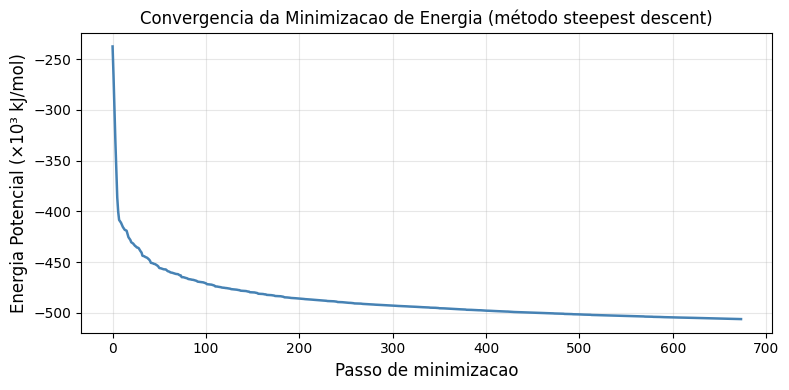

Passos: 533
Energia inicial: -237.4 × 10³ kJ/mol
Energia final:   -506.1 × 10³ kJ/mol
Convergencia: Fmax < 500 kJ/mol/nm atingido


In [ ]:
# Visualizacao: convergencia da minimizacao de energia
import numpy as np
import matplotlib.pyplot as plt

data = []
with open('potential.xvg') as f:
    for line in f:
        if not line.startswith(('#', '@')):
            parts = line.split()
            if len(parts) >= 2:
                try:
                    data.append([float(parts[0]), float(parts[1])])
                except ValueError:
                    pass
data = np.array(data)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(data[:, 0], data[:, 1] / 1000, color='steelblue', lw=1.8)
ax.set_xlabel('Passo de minimizacao', fontsize=12)
ax.set_ylabel('Energia Potencial (×10³ kJ/mol)', fontsize=12)
ax.set_title('Convergencia da Minimizacao de Energia (método steepest descent)', fontsize=12)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.savefig('minimizacao_energia.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Passos: {len(data)}")
print(f"Energia inicial: {data[0,1]/1000:.1f} × 10³ kJ/mol")
print(f"Energia final:   {data[-1,1]/1000:.1f} × 10³ kJ/mol")
print(f"Convergencia: Fmax < 500 kJ/mol/nm atingido")

## Passo 5 — Equilibração NVT (20 ps)

Estabiliza a **temperatura** a 298 K com o termostato V-rescale (Bussi et al.).

As posições dos átomos pesados da proteína são **restringidas** (`define = -DPOSRES`) para evitar deformações durante o aquecimento inicial. Volume e número de partículas são constantes.


In [ ]:
import os
if not cached(['nvt.gro', 'nvt.cpt'], 'NVT (20 ps)'):
    os.system('gmx grompp -f nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr')
    os.system('gmx mdrun -v -deffnm nvt')


  ja pronto: NVT (20 ps)


In [ ]:
# Visualizacao: sistema apos equilibracao NVT (20 ps)
with open('nvt.gro') as f:
    gro = f.read()
viz_gro(gro, 'Apos NVT — temperatura = 298 K')


Apos NVT — temperatura = 298 K


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
import os, py3Dmol
# Extrair trajetoria NVT — proteina apenas, stride 2 ps (10 frames / 20 ps)
if not cached(['nvt_anim_prot.pdb'], 'NVT animation'):
    os.system("echo '1' | gmx trjconv -s nvt.tpr -f nvt.trr -o nvt_anim_prot.pdb -dt 2 -quiet 2>/dev/null")

with open('nvt_anim_prot.pdb') as f:
    pdb_anim = f.read()

view = py3Dmol.view(width=1050, height=630)
view.addModelsAsFrames(pdb_anim, 'pdb')
view.setStyle({}, {'cartoon': {'colorscheme': SS_CS},
                    'stick':   {'colorscheme': SS_CS, 'radius': 0.10}})
view.animate({'loop': 'forward', 'reps': 0, 'step': 1})
view.setBackgroundColor('white')
view.zoomTo()
view.show()
print(f'NVT | {pdb_anim.count("MODEL")} frames | stride 2 ps | proteina | helix=vermelho sheet=azul loop=cinza')


  ja pronto: NVT animation


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

NVT | 11 frames | stride 2 ps | proteina | helix=vermelho sheet=azul loop=cinza


In [ ]:
# Verificar temperatura — selecione '16' (Temperature) e '0' para encerrar
!echo -e "16\n0" | gmx energy -f nvt.edr -o temperature.xvg


              :-) GROMACS - gmx energy, 2021.4-Ubuntu-2021.4-2 (-:

                            GROMACS is written by:
     Andrey Alekseenko              Emile Apol              Rossen Apostolov     
         Paul Bauer           Herman J.C. Berendsen           Par Bjelkmar       
       Christian Blau           Viacheslav Bolnykh             Kevin Boyd        
     Aldert van Buuren           Rudi van Drunen             Anton Feenstra      
    Gilles Gouaillardet             Alan Gray               Gerrit Groenhof      
       Anca Hamuraru            Vincent Hindriksen          M. Eric Irrgang      
      Aleksei Iupinov           Christoph Junghans             Joe Jordan        
    Dimitrios Karkoulis            Peter Kasson                Jiri Kraus        
      Carsten Kutzner              Per Larsson              Justin A. Lemkul     
       Viveca Lindahl            Magnus Lundborg             Erik Marklund       
        Pascal Merz             Pieter Meulenhoff            

## Passo 6 — Equilibração NPT (50 ps)

Estabiliza a **pressão** a 1 bar com o barostato C-rescale (recomendado para CHARMM36m).

O estado anterior é carregado via `-t nvt.cpt` (checkpoint) para continuidade exata. As restrições de posição continuam ativas.


In [ ]:
import os
if not cached(['npt.gro', 'npt.cpt'], 'NPT (50 ps)'):
    os.system('gmx grompp -f npt.mdp -c nvt.gro -r em.gro -t nvt.cpt -p topol.top -o npt.tpr')
    os.system('gmx mdrun -v -deffnm npt')


  ja pronto: NPT (50 ps)


In [ ]:
# Visualizacao: sistema apos equilibracao NPT (50 ps)
with open('npt.gro') as f:
    gro = f.read()
viz_gro(gro, 'Apos NPT — pressao = 1 bar | volume pode ter mudado ligeiramente')


Apos NPT — pressao = 1 bar | volume pode ter mudado ligeiramente


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
import os, py3Dmol
# Extrair trajetoria NPT — proteina apenas, stride 5 ps (10 frames / 50 ps)
if not cached(['npt_anim_prot.pdb'], 'NPT animation'):
    os.system("echo '1' | gmx trjconv -s npt.tpr -f npt.trr -o npt_anim_prot.pdb -dt 5 -quiet 2>/dev/null")

with open('npt_anim_prot.pdb') as f:
    pdb_anim = f.read()

view = py3Dmol.view(width=1050, height=630)
view.addModelsAsFrames(pdb_anim, 'pdb')
view.setStyle({}, {'cartoon': {'colorscheme': SS_CS},
                    'stick':   {'colorscheme': SS_CS, 'radius': 0.10}})
view.animate({'loop': 'forward', 'reps': 0, 'step': 1})
view.setBackgroundColor('white')
view.zoomTo()
view.show()
print(f'NPT | {pdb_anim.count("MODEL")} frames | stride 5 ps | proteina | helix=vermelho sheet=azul loop=cinza')


  ja pronto: NPT animation


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

NPT | 11 frames | stride 5 ps | proteina | helix=vermelho sheet=azul loop=cinza


In [ ]:
# Verificar pressao — selecione '17' (Pressure) e '0' para encerrar
!echo -e "17\n0" | gmx energy -f npt.edr -o pressure.xvg


              :-) GROMACS - gmx energy, 2021.4-Ubuntu-2021.4-2 (-:

                            GROMACS is written by:
     Andrey Alekseenko              Emile Apol              Rossen Apostolov     
         Paul Bauer           Herman J.C. Berendsen           Par Bjelkmar       
       Christian Blau           Viacheslav Bolnykh             Kevin Boyd        
     Aldert van Buuren           Rudi van Drunen             Anton Feenstra      
    Gilles Gouaillardet             Alan Gray               Gerrit Groenhof      
       Anca Hamuraru            Vincent Hindriksen          M. Eric Irrgang      
      Aleksei Iupinov           Christoph Junghans             Joe Jordan        
    Dimitrios Karkoulis            Peter Kasson                Jiri Kraus        
      Carsten Kutzner              Per Larsson              Justin A. Lemkul     
       Viveca Lindahl            Magnus Lundborg             Erik Marklund       
        Pascal Merz             Pieter Meulenhoff            

## Passo 7 — Simulação Produtiva (100 ps)

Com o sistema equilibrado, as restrições são removidas e a coleta de dados começa.

> **Tempo de execução estimado:** ~5–8 min na CPU do Colab de 100 ps na CPU do Colab.


In [ ]:
import os
if not cached(['md_0_100.xtc', 'md_0_100.tpr'], 'MD produtiva (100 ps)'):
    os.system('gmx grompp -f md.mdp -c npt.gro -t npt.cpt -p topol.top -o md_0_100.tpr')
    os.system('gmx mdrun -v -deffnm md_0_100')


  ja pronto: MD produtiva (100 ps)


In [ ]:
import os
if not cached(['md_last.pdb'], 'ultimo frame MD'):
    # md_0_100.gro e gerado automaticamente pelo mdrun (ultimo frame)
    os.system('gmx editconf -f md_0_100.gro -o md_last.pdb 2>&1 | tail -2')


  ja pronto: ultimo frame MD


In [ ]:
import os, py3Dmol
# Extrair trajetoria MD produtiva — proteina apenas, stride 5 ps (20 frames / 100 ps)
if not cached(['md_raw_anim_prot.pdb'], 'MD raw animation'):
    os.system("echo '1' | gmx trjconv -s md_0_100.tpr -f md_0_100.xtc -o md_raw_anim_prot.pdb -dt 5 -quiet 2>/dev/null")

with open('md_raw_anim_prot.pdb') as f:
    pdb_anim = f.read()

view = py3Dmol.view(width=1050, height=630)
view.addModelsAsFrames(pdb_anim, 'pdb')
view.setStyle({}, {'cartoon': {'colorscheme': SS_CS},
                    'stick':   {'colorscheme': SS_CS, 'radius': 0.10}})
view.animate({'loop': 'forward', 'reps': 0, 'step': 1})
view.setBackgroundColor('white')
view.zoomTo()
view.show()
print(f'MD produtiva | {pdb_anim.count("MODEL")} frames | stride 5 ps | proteina | antes do ajuste de posicao')


  ja pronto: MD raw animation


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

MD produtiva | 4 frames | stride 5 ps | proteina | antes do ajuste de posicao


In [ ]:
import os, py3Dmol
# Animacao sistema completo — proteina + agua + ions
# stride 20 ps = 5 frames (necessario para nao travar com ~30k atomos)
if not cached(['md_full_anim.pdb'], 'MD full system animation'):
    os.system("echo '0' | gmx trjconv -s md_0_100.tpr -f md_0_100.xtc -o md_full_anim.pdb -dt 20 -quiet 2>/dev/null")

with open('md_full_anim.pdb') as f:
    pdb_full = f.read()

view = py3Dmol.view(width=1050, height=630)
view.addModelsAsFrames(pdb_full, 'pdb')

prot = {'not': {'resn': ['SOL','NA','CL']}}
view.setStyle(prot, {'cartoon': {'colorscheme': SS_CS},
                     'stick':   {'colorscheme': SS_CS, 'radius': 0.12}})
view.setStyle({'resn': 'SOL'},
              {'stick': {'color': '#99ccff', 'radius': 0.12, 'opacity': 0.18}})
view.addStyle({'resn': 'NA'}, {'sphere': {'color': '#3355ff', 'radius': 0.45}})
view.addStyle({'resn': 'CL'}, {'sphere': {'color': '#22bb44', 'radius': 0.50}})

view.animate({'loop': 'forward', 'reps': 0, 'step': 1})
view.setBackgroundColor('#f0f4f8')
view.zoomTo()
view.show()
print(f'Sistema completo | {pdb_full.count("MODEL")} frames | stride 20 ps | proteina + agua + ions')


  ja pronto: MD full system animation


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Sistema completo | 2 frames | stride 20 ps | proteina + agua + ions


In [ ]:
# Celula reservada — extensao de trajetoria nao necessaria para 100 ps
print('Simulacao produtiva concluida: md_0_100.xtc')
!ls -lh md_0_100.xtc md_0_100.tpr


Simulacao produtiva concluida: md_0_100.xtc
-rw------- 1 root root  1.3M Mar 24 14:48 md_0_100.tpr
-rw------- 1 root root 1010K Mar 24 16:03 md_0_100.xtc


# Análise da Simulação

> **Primeiro passo sempre:** Inspecionar visualmente a trajetória no VMD ou PyMOL antes de qualquer análise quantitativa.


## Análise 1 — Pré-processamento da Trajetória

1. **Reimagear** para remover artefatos de contorno periódico (`trjconv -pbc mol`)
2. **Ajustar** rotação e translação globais para análises estruturais (`trjconv -fit rot+trans`)


In [ ]:
import os
if not cached(['md_reimaged.xtc'], 'reimagem da trajetoria'):
    os.system('echo -e "1\n0" | gmx trjconv -s md_0_100.tpr -f md_0_100.xtc -o md_reimaged.xtc -pbc mol -ur compact -center')

if not cached(['md_fit.xtc'], 'ajuste rot+trans'):
    os.system('echo -e "4\n0" | gmx trjconv -s md_0_100.tpr -f md_reimaged.xtc -o md_fit.xtc -fit rot+trans')


  ja pronto: reimagem da trajetoria
  ja pronto: ajuste rot+trans


In [ ]:
import os, py3Dmol
# Animacao da trajetoria ajustada (rot+trans removidos)
# group 1 = Protein (selecionar do System em md_fit.xtc)
if not cached(['md_anim_prot.pdb'], 'md_fit animation'):
    os.system("echo '1' | gmx trjconv -s md_0_100.tpr -f md_fit.xtc -o md_anim_prot.pdb -dt 5 2>&1 | tail -3")

if not os.path.exists('md_anim_prot.pdb'):
    print('AVISO: md_anim_prot.pdb nao gerado — verifique a celula de pre-processamento (Analise 1).')
else:
    with open('md_anim_prot.pdb') as f:
        pdb_anim = f.read()

    view = py3Dmol.view(width=1050, height=630)
    view.addModelsAsFrames(pdb_anim, 'pdb')
    view.setStyle({}, {'cartoon': {'colorscheme': SS_CS},
                        'stick':   {'colorscheme': SS_CS, 'radius': 0.10}})
    view.animate({'loop': 'forward', 'reps': 0, 'step': 1})
    view.setBackgroundColor('white')
    view.zoomTo()
    view.show()
    print(f'Trajetoria ajustada: {pdb_anim.count("MODEL")} frames | stride 5 ps | rot+trans removidos')


  ja pronto: md_fit animation


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Trajetoria ajustada: 4 frames | stride 5 ps | rot+trans removidos


## Análise 2 — RMSD (Root-Mean-Square Deviation)

Desvio estrutural em relação à estrutura de referência ao longo do tempo. Use **Backbone** (N, Cα, C) para ajuste e cálculo.

Valores típicos para proteínas estáveis: **0.1–0.2 nm** (1–2 Å).


In [ ]:
# Selecione '4' (Backbone) para ajuste e para o calculo
!echo -e "4\n4" | gmx rms -s md_0_100.tpr -f md_fit.xtc -o rmsd.xvg


               :-) GROMACS - gmx rms, 2021.4-Ubuntu-2021.4-2 (-:

                            GROMACS is written by:
     Andrey Alekseenko              Emile Apol              Rossen Apostolov     
         Paul Bauer           Herman J.C. Berendsen           Par Bjelkmar       
       Christian Blau           Viacheslav Bolnykh             Kevin Boyd        
     Aldert van Buuren           Rudi van Drunen             Anton Feenstra      
    Gilles Gouaillardet             Alan Gray               Gerrit Groenhof      
       Anca Hamuraru            Vincent Hindriksen          M. Eric Irrgang      
      Aleksei Iupinov           Christoph Junghans             Joe Jordan        
    Dimitrios Karkoulis            Peter Kasson                Jiri Kraus        
      Carsten Kutzner              Per Larsson              Justin A. Lemkul     
       Viveca Lindahl            Magnus Lundborg             Erik Marklund       
        Pascal Merz             Pieter Meulenhoff            Te

## Análise 3 — RMSF (Root-Mean-Square Fluctuation)

Flexibilidade de cada resíduo ao redor de sua posição média. A opção `-res` calcula um valor por resíduo.

- Alta flexibilidade (>0.3 nm): loops e terminais
- Baixa flexibilidade (<0.15 nm): α-hélices e folhas-β


In [ ]:
# Selecione '3' (C-alpha)
!echo "3" | gmx rmsf -s md_0_100.tpr -f md_fit.xtc -o rmsf.xvg -res


               :-) GROMACS - gmx rmsf, 2021.4-Ubuntu-2021.4-2 (-:

                            GROMACS is written by:
     Andrey Alekseenko              Emile Apol              Rossen Apostolov     
         Paul Bauer           Herman J.C. Berendsen           Par Bjelkmar       
       Christian Blau           Viacheslav Bolnykh             Kevin Boyd        
     Aldert van Buuren           Rudi van Drunen             Anton Feenstra      
    Gilles Gouaillardet             Alan Gray               Gerrit Groenhof      
       Anca Hamuraru            Vincent Hindriksen          M. Eric Irrgang      
      Aleksei Iupinov           Christoph Junghans             Joe Jordan        
    Dimitrios Karkoulis            Peter Kasson                Jiri Kraus        
      Carsten Kutzner              Per Larsson              Justin A. Lemkul     
       Viveca Lindahl            Magnus Lundborg             Erik Marklund       
        Pascal Merz             Pieter Meulenhoff            T

## Análise 4 — Estrutura Secundária (DSSP)

O algoritmo DSSP classifica cada resíduo, a cada quadro, em um elemento de estrutura secundária: hélice-α, fita-β, volta ou espiral. O resultado é um mapa de calor **resíduo × tempo** — equivalente à Figura 8 do tutorial Lemkul 2024.

> **GROMACS 2021 (Colab):** requer o pacote `dssp` instalado via apt e o comando `gmx do_dssp` (o `gmx dssp` só existe no GROMACS 2023+).

In [93]:
import os, subprocess
import numpy as np

# MDTraj tem DSSP nativo — sem dependencia de binario externo
subprocess.run(['pip', 'install', '-q', 'mdtraj'], capture_output=True)

if not os.path.exists('md_fit.xtc') or not os.path.exists('md_0_100.gro'):
    print('AVISO: md_fit.xtc ou md_0_100.gro nao encontrado.')
elif not cached(['ss_mdtraj.npy', 'ss_times.npy'], 'DSSP'):
    import mdtraj as md
    print('Carregando trajetoria...')
    traj = md.load('md_fit.xtc', top='md_0_100.gro')
    prot = traj.atom_slice(traj.topology.select('protein'))
    print(f'{prot.n_frames} frames | {prot.n_residues} residuos')
    dssp = md.compute_dssp(prot, simplified=False)  # shape: (frames, residuos)
    np.save('ss_mdtraj.npy', dssp)
    np.save('ss_times.npy', traj.time)
    print('DSSP calculado.')

print('ss_mdtraj.npy:', 'OK' if os.path.exists('ss_mdtraj.npy') else 'nao gerado')


  ja pronto: DSSP
ss_mdtraj.npy: OK


## Análise 5 — Raio de Giração (Rg)

O raio de giração mede a **dispersão de massa** em torno do centro de massa da proteína. Uma proteína bem enovelada mantém Rg estável; desnaturação ou abertura de domínio eleva Rg.

`gmx gyrate` calcula Rg total e por componente (x, y, z).

In [94]:
import os

if not cached(['gyrate.xvg'], 'Raio de Giração'):
    os.system('echo "1" | gmx gyrate -s md_0_100.tpr -f md_fit.xtc -o gyrate.xvg 2>&1 | tail -3')


  ja pronto: Raio de Giração


## Análise 6 — Mapa de Contatos (mdmat)

`gmx mdmat` calcula a distância mínima entre pares de resíduos ao longo da trajetória. Com `-mean`, produz o **mapa médio de distâncias**: valores próximos de zero indicam contato persistente entre resíduos.

> Útil para identificar contatos estruturais conservados e avaliar a estabilidade de interfaces.

In [95]:
import os

if not cached(['mdmat_mean.xpm'], 'mdmat'):
    os.system('echo "1" | gmx mdmat -s md_0_100.tpr -f md_fit.xtc -mean mdmat_mean.xpm 2>&1 | tail -3')


  ja pronto: mdmat


## Análise 7 — Ligações de Hidrogênio

Critério geométrico: distância doador–aceptor ≤ 3.5 Å, ângulo H–doador–aceptor ≤ 30°. O número total de ligações H intramoleculares reflete a estabilidade da rede de contatos polares da proteína.

> Selecione **Protein (grupo 1)** como doador e aceptor.

In [96]:
import os

# Selecione '1' (Protein) como doador e '1' (Protein) como aceptor
if not cached(['hbond_total.xvg'], 'Ligações de Hidrogênio'):
    os.system('echo -e "1\n1" | gmx hbond -s md_0_100.tpr -f md_fit.xtc -num hbond_total.xvg 2>&1 | tail -5')


  ja pronto: Ligações de Hidrogênio


## Visualização das Análises

As células abaixo exibem cada análise individualmente, com uma breve explicação para orientar a interpretação dos resultados.

In [97]:
import os, re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def read_xvg(filepath):
    data = []
    with open(filepath) as f:
        for line in f:
            if not line.startswith(('#', '@')):
                parts = line.split()
                if len(parts) >= 2:
                    try: data.append([float(x) for x in parts[:2]])
                    except: pass
    return np.array(data)

def moving_avg(d, n=20):
    win = max(1, len(d) // n)
    ma  = np.convolve(d[:, 1], np.ones(win) / win, mode='valid')
    return d[win-1:, 0], ma

def _xpm_find_dim(strings):
    for i, s in enumerate(strings):
        parts = s.split()
        if len(parts) == 4:
            try:
                return (i,) + tuple(map(int, parts))
            except ValueError:
                continue
    raise ValueError('Nao foi possivel encontrar string de dimensoes no XPM')

def xpm_to_distance_matrix(fname):
    with open(fname) as f:
        content = f.read()
    strings = re.findall(r'"([^"]*)"', content)
    i0, w, h, nc, cpp = _xpm_find_dim(strings)
    dist_values, char_list = [], []
    for i in range(i0 + 1, i0 + 1 + nc):
        s = strings[i]; key = s[:cpp]
        m = re.search(r'([\d.]+)\s*nm', s)
        dist_values.append(float(m.group(1)) if m else float(i - i0 - 1) / max(nc - 1, 1))
        char_list.append(key)
    char_to_i = {c: i for i, c in enumerate(char_list)}
    data = strings[i0 + 1 + nc: i0 + 1 + nc + h]
    arr = np.zeros((h, w))
    for r, row in enumerate(data):
        for c in range(w):
            arr[r, c] = dist_values[char_to_i.get(row[c*cpp:(c+1)*cpp], 0)]
    return arr[::-1]

### RMSD — Desvio Quadrático Médio

O **RMSD** (*Root-Mean-Square Deviation*) mede o desvio médio dos átomos do backbone em relação à estrutura de referência (frame inicial). É o principal indicador de convergência da simulação.

- Um RMSD que **cresce e depois estabiliza** indica que o sistema equilibrou.
- Um RMSD que **continua crescendo** sugere que a simulação não convergiu ou que o sistema está passando por uma transição conformacional.
- Para proteínas globulares pequenas (como a ubiquitina) em simulações curtas, valores abaixo de **0,3 nm** são esperados.

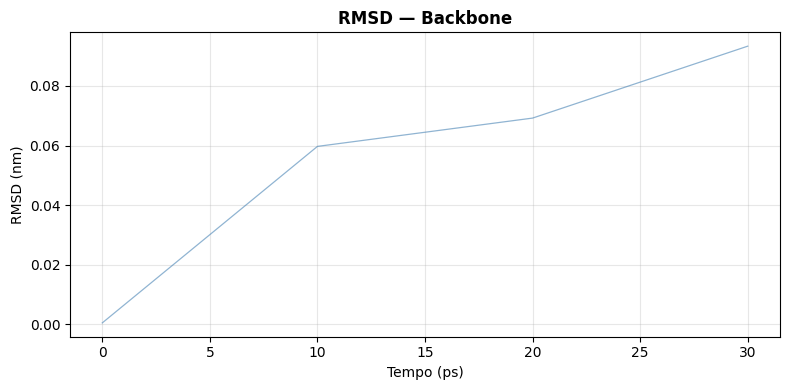

In [98]:
if os.path.exists('rmsd.xvg'):
    d = read_xvg('rmsd.xvg')
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(d[:, 0], d[:, 1], lw=0.9, color='steelblue', alpha=0.6)
    if len(d) > 20:
        tx, ma = moving_avg(d)
        ax.plot(tx, ma, lw=2.0, color='tomato', label='média móvel')
        ax.legend()
    ax.set_xlabel('Tempo (ps)'); ax.set_ylabel('RMSD (nm)')
    ax.set_title('RMSD — Backbone', fontweight='bold'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig('plot_rmsd.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('rmsd.xvg nao encontrado.')

### RMSF — Flutuação Quadrática Média por Resíduo

O **RMSF** (*Root-Mean-Square Fluctuation*) quantifica a mobilidade média de cada resíduo ao longo da simulação (calculado sobre os átomos Cα).

- **Picos elevados** indicam regiões flexíveis: alças (*loops*), terminais N e C.
- **Regiões planas e baixas** correspondem a estruturas secundárias estáveis (hélices α, fitas β).
- Comparando o perfil de RMSF com a estrutura 3D, é possível identificar quais elementos estruturais mais contribuem para a flexibilidade da proteína.

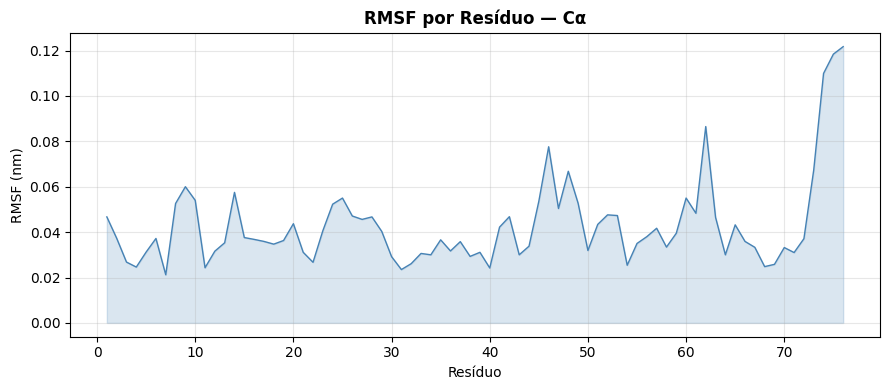

In [99]:
if os.path.exists('rmsf.xvg'):
    d = read_xvg('rmsf.xvg')
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(d[:, 0], d[:, 1], lw=1.0, color='steelblue')
    ax.fill_between(d[:, 0], d[:, 1], alpha=0.2, color='steelblue')
    ax.set_xlabel('Resíduo'); ax.set_ylabel('RMSF (nm)')
    ax.set_title('RMSF por Resíduo — Cα', fontweight='bold'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig('plot_rmsf.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('rmsf.xvg nao encontrado.')

### DSSP — Estrutura Secundária ao Longo do Tempo

O algoritmo **DSSP** (*Define Secondary Structure of Proteins*) classifica cada resíduo em cada frame quanto ao tipo de estrutura secundária, com base em padrões de ligações de hidrogênio.

O mapa usa três grupos de cores:
- **Vermelho** — Hélices (α-hélice, hélice 3₁₀, π-hélice)
- **Azul** — Fitas β e pontes β
- **Branco** — Regiões desestruturadas (espiral, voltas, alças)

Cada linha representa um resíduo; cada coluna, um frame da simulação. Faixas contínuas de cor indicam elementos estáveis; regiões mescladas sugerem flutuações conformacionais.

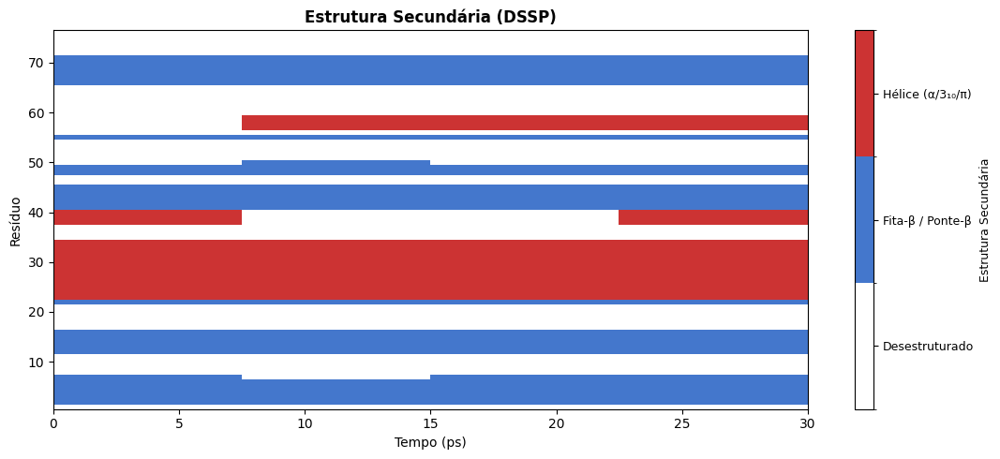

In [100]:
if os.path.exists('ss_mdtraj.npy') and os.path.exists('ss_times.npy'):
    dssp  = np.load('ss_mdtraj.npy', allow_pickle=True)
    times = np.load('ss_times.npy')

    # Simplified: helix=red, strand=blue, unstructured=white
    def ss_to_group(s):
        if s in ('H', 'G', 'I'):   return 2  # helix
        if s in ('E', 'B'):         return 1  # strand/sheet
        return 0                               # coil/loop/unstructured

    arr = np.vectorize(ss_to_group)(dssp).T

    cmap = mcolors.ListedColormap(['#FFFFFF', '#4477CC', '#CC3333'])
    norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)

    fig, ax = plt.subplots(figsize=(11, 5))
    ax.imshow(arr, aspect='auto', cmap=cmap, norm=norm,
              origin='lower', extent=[times[0], times[-1], 0.5, arr.shape[0] + 0.5])
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm); sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, ticks=[0, 1, 2])
    cbar.ax.set_yticklabels(['Desestruturado', 'Fita-\u03b2 / Ponte-\u03b2', 'H\u00e9lice (\u03b1/3\u2081\u2080/\u03c0)'], fontsize=9)
    cbar.set_label('Estrutura Secund\u00e1ria', fontsize=9)
    ax.set_xlabel('Tempo (ps)'); ax.set_ylabel('Res\u00edduo')
    ax.set_title('Estrutura Secund\u00e1ria (DSSP)', fontweight='bold')
    plt.tight_layout(); plt.savefig('plot_dssp.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('ss_mdtraj.npy nao encontrado \u2014 execute a c\u00e9lula DSSP primeiro.')

### Raio de Giração (Rg)

O **raio de giração** é uma medida de compacidade da proteína: corresponde à raiz quadrada da média ponderada pela massa do quadrado da distância de cada átomo ao centro de massa.

- Um Rg **estável** indica que a proteína manteve sua compacidade ao longo da simulação.
- Um Rg **crescente** pode indicar desnaturação ou expansão da estrutura.
- Para a ubiquitina (76 resíduos), valores entre **1,1 e 1,3 nm** são esperados em condições fisiológicas.

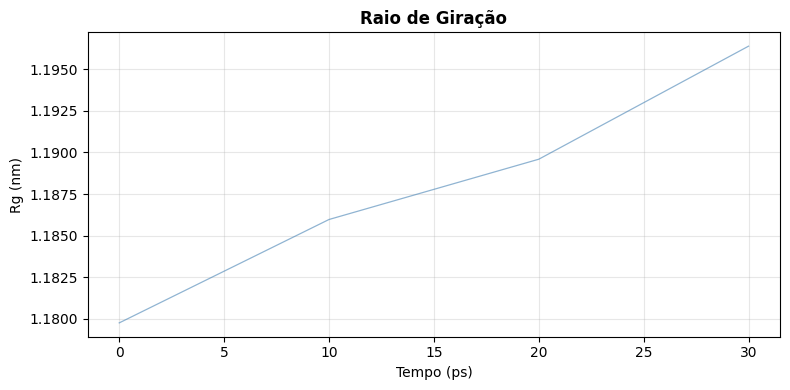

In [101]:
if os.path.exists('gyrate.xvg'):
    d = read_xvg('gyrate.xvg')
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(d[:, 0], d[:, 1], lw=0.9, color='steelblue', alpha=0.6)
    if len(d) > 20:
        tx, ma = moving_avg(d)
        ax.plot(tx, ma, lw=2.0, color='tomato', label='m\u00e9dia m\u00f3vel')
        ax.legend()
    ax.set_xlabel('Tempo (ps)'); ax.set_ylabel('Rg (nm)')
    ax.set_title('Raio de Gira\u00e7\u00e3o', fontweight='bold'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig('plot_gyrate.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('gyrate.xvg nao encontrado.')

### Mapa de Contatos (mdmat)

O **mapa de contatos** (*contact map*) exibe a distância mínima média entre todos os pares de resíduos ao longo da simulação.

- Cores **verdes/escuras** indicam pares próximos (< 0,3 nm) — contatos efetivos.
- Cores **amarelas/vermelhas** indicam pares distantes — sem contato.
- Padrões **fora da diagonal** revelam contatos entre elementos estruturais distantes na sequência:
  - Faixas **paralelas à diagonal** → fitas β paralelas
  - Faixas **perpendiculares à diagonal** → fitas β antiparalelas
  - Blocos → domínios compactos ou nós de hélice

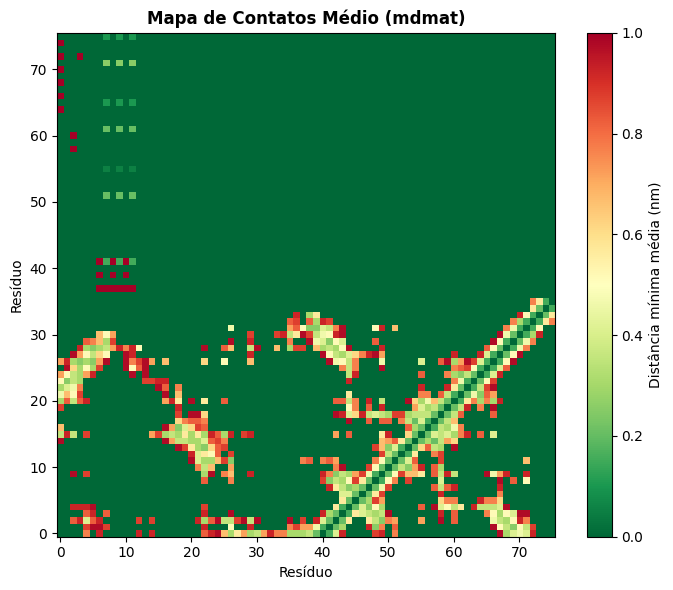

In [102]:
if os.path.exists('mdmat_mean.xpm'):
    mat = xpm_to_distance_matrix('mdmat_mean.xpm')
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(mat, cmap='RdYlGn_r', vmin=0, aspect='auto', origin='lower')
    plt.colorbar(im, ax=ax, label='Dist\u00e2ncia m\u00ednima m\u00e9dia (nm)')
    ax.set_xlabel('Res\u00edduo'); ax.set_ylabel('Res\u00edduo')
    ax.set_title('Mapa de Contatos M\u00e9dio (mdmat)', fontweight='bold')
    plt.tight_layout(); plt.savefig('plot_mdmat.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('mdmat_mean.xpm nao encontrado.')

### Ligações de Hidrogênio Intramoleculares

As **ligações de hidrogênio** (pontes H) são calculadas com critério geométrico:
distância doador–aceptor < 0,35 nm e ângulo D–H···A > 150°.

O gráfico mostra o número total de pontes H intramoleculares na proteína ao longo do tempo.

- Um número **estável** de pontes H indica preservação da estrutura secundária.
- **Oscilações** podem refletir flutuações normais ou, em casos extremos, transições conformacionais.
- Para a ubiquitina com 76 resíduos e estrutura secundária rica em hélice α e fita β, esperam-se valores entre **40 e 70** pontes H internas.

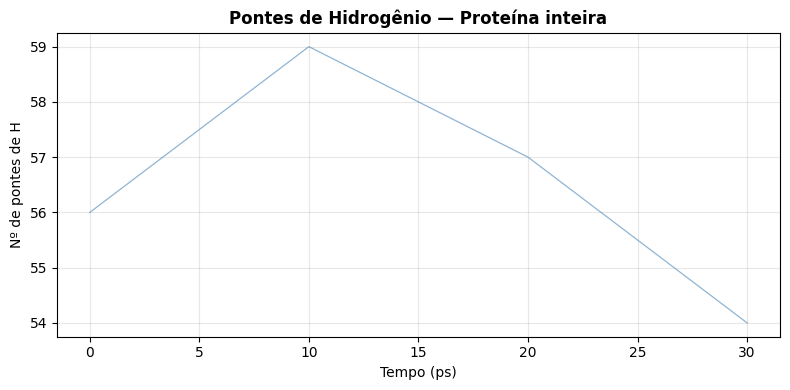

In [103]:
if os.path.exists('hbond_total.xvg'):
    d = read_xvg('hbond_total.xvg')
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(d[:, 0], d[:, 1], lw=0.9, color='steelblue', alpha=0.6)
    if len(d) > 20:
        tx, ma = moving_avg(d)
        ax.plot(tx, ma, lw=2.0, color='tomato', label='m\u00e9dia m\u00f3vel')
        ax.legend()
    ax.set_xlabel('Tempo (ps)'); ax.set_ylabel('N\u00ba de pontes de H')
    ax.set_title('Pontes de Hidrog\u00eanio \u2014 Prote\u00edna inteira', fontweight='bold'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig('plot_hbond.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('hbond_total.xvg nao encontrado.')

## Referências

- Lemkul, J. A. *J. Phys. Chem. B* **2024**, *128*, 9418–9435. https://doi.org/10.1021/acs.jpcb.4c04901
- Repositório de inputs: https://github.com/Lemkul-Lab/gmx_tutorials_jpcb
- GROMACS Manual: https://manual.gromacs.org/
- CHARMM36m: http://mackerell.umaryland.edu/charmm_ff.shtml#gromacs
